# 04 — Feature Engineering & Feature Selection
**Pipeline stage:** `Time-Series Analysis → Feature Engineering → Feature Selection → Regression Model → ...`

This is the most important notebook of the data-preparation phase: it turns
`data/processed/ILA_cleaned.csv` into a genuine **supervised learning table** for drift
prediction, then screens the engineered features with eight independent selection
techniques so that Notebook 05 trains on a justified, non-redundant feature set.

**Target construction.** The dataset has no explicit "future value" column, so the
regression target is built explicitly here: for each instrument, sorted chronologically,
the target for row *t* is the `valeur_reference` (and `erreur`) recorded at the *next*
campaign for that same instrument. Rows that are the last observation of their instrument
(no known future) get a missing target and are kept aside as *inference-only* rows — they
cannot be used to train or evaluate a supervised model, only to serve a live prediction
once a model exists.

**Outputs:**
- `data/processed/ILA_features.csv` (full engineered feature table, with target)
- `data/processed/ILA_features_selected.csv` (target + retained features only)
- `reports/quality/feature_selection_report.xlsx`
- Figures in `reports/figures/04_feature_engineering_selection/`


## 1. Imports

In [1]:

import sys, logging
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import (VarianceThreshold, mutual_info_regression,
                                        SelectKBest, f_regression, RFE)
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import shap

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_style("whitegrid")
plt.rcParams["figure.facecolor"] = "white"
RANDOM_STATE = 42

print("Imports OK -", datetime.now().isoformat(timespec="seconds"))


Imports OK - 2026-08-23T00:03:39


/home/claude/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Configuration

In [2]:

project_root = next(c for c in [Path.cwd(), Path.cwd().parent] if (c / "config" / "config.yaml").exists())
sys.path.insert(0, str(project_root))

from src.utils.config import load_config
from src.utils.data_discovery import discover_dataset

cfg = load_config()
DATA_PROCESSED = project_root / cfg["paths"]["data_processed"]
REPORTS_FIGURES = project_root / cfg["paths"]["reports_figures"] / "04_feature_engineering_selection"
REPORTS_QUALITY = project_root / cfg["paths"]["reports_quality"]
LOGS_DIR = project_root / cfg["paths"]["logs"]
for d in [REPORTS_FIGURES, LOGS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s",
    handlers=[logging.FileHandler(LOGS_DIR / "04_feature_engineering_selection.log", mode="w"),
              logging.StreamHandler(sys.stdout)],
)
logger = logging.getLogger("04_features")


## 3. Load Cleaned Dataset

In [3]:

DATASET_PATH, _ = discover_dataset(
    search_dirs=[DATA_PROCESSED],
    expected_columns=cfg["expected_columns"],
    exclude_keywords=cfg["dataset_discovery"]["exclude_keywords"],
    split_keywords=cfg["dataset_discovery"]["split_keywords"],
    prefer_split=False, logger=logger,
)
print(f">>> Dataset selected: {DATASET_PATH.relative_to(project_root)}")
df = pd.read_csv(DATASET_PATH)
df = df.sort_values(["id_instrument", "annee", "point_numeric"]).reset_index(drop=True)
print(f"Shape: {df.shape}")


2026-08-23 00:03:39,084 | INFO | Found 6 candidate CSV file(s) in [PosixPath('/home/claude/project2/metrology-ai-pipeline/data/processed')]


2026-08-23 00:03:39,103 | INFO | Selected dataset (prefer_split=False, full schema match): ILA_cleaned.csv


2026-08-23 00:03:39,104 | INFO | DATASET SELECTED: /home/claude/project2/metrology-ai-pipeline/data/processed/ILA_cleaned.csv (763 rows, 12/12 expected columns matched)


>>> Dataset selected: data/processed/ILA_cleaned.csv
Shape: (763, 23)


## 4. Feature Engineering

### 4.1 Core metrology quantities (recap from Notebook 03)

In [4]:

df["erreur"] = df["consigne"] - df["valeur_reference"]
df["distance_to_EMT"] = df.apply(
    lambda r: min(r["min"] - r["EMT_basse"], r["EMT_haute"] - r["max"])
    if pd.notna(r["min"]) and pd.notna(r["max"]) and pd.notna(r["EMT_basse"]) and pd.notna(r["EMT_haute"])
    else np.nan, axis=1
)
df["uncertainty_ratio"] = df["incertitude"] / (df["EMT_haute"] - df["EMT_basse"])
df["emt_width"] = df["EMT_haute"] - df["EMT_basse"]
df["health_index"] = df["distance_to_EMT"] / df["emt_width"]
df["confidence_score"] = 1 / (1 + df["uncertainty_ratio"].abs())
print("Core quantities computed:", ["erreur", "distance_to_EMT", "uncertainty_ratio", "health_index", "confidence_score"])


Core quantities computed: ['erreur', 'distance_to_EMT', 'uncertainty_ratio', 'health_index', 'confidence_score']


### 4.2 Time / history features (per instrument, chronologically ordered)

Every feature below uses **only current-and-past** information for a given row (via
`.shift()`, `.expanding()` or `.rolling()` after grouping by `id_instrument`), which is
what makes them legitimate predictors of the *next* value constructed as the target in
section 4.4 — no future information leaks into a feature.


In [5]:

g = df.groupby("id_instrument", group_keys=False)

df["chrono_rank_in_instrument"] = g.cumcount()
df["calibration_count"] = df["chrono_rank_in_instrument"] + 1           # measurements seen so far, incl. current
df["time_since_last_calibration"] = g["annee"].diff()                    # NaN for first record of an instrument
df["instrument_age_years"] = df["annee"] - g["annee"].transform("min")

df["lag1_valeur_reference"] = g["valeur_reference"].shift(1)
df["lag1_erreur"] = g["erreur"].shift(1)
df["delta_measurement"] = df["valeur_reference"] - df["lag1_valeur_reference"]
df["drift_rate"] = (df["delta_measurement"] / df["time_since_last_calibration"]).replace([np.inf, -np.inf], np.nan)

df["rolling_mean_3"] = g["valeur_reference"].transform(lambda s: s.rolling(3, min_periods=1).mean())
df["rolling_std_3"] = g["valeur_reference"].transform(lambda s: s.rolling(3, min_periods=1).std())
df["rolling_median_3"] = g["valeur_reference"].transform(lambda s: s.rolling(3, min_periods=1).median())
df["rolling_max_3"] = g["valeur_reference"].transform(lambda s: s.rolling(3, min_periods=1).max())
df["rolling_min_3"] = g["valeur_reference"].transform(lambda s: s.rolling(3, min_periods=1).min())
df["moving_average_5"] = g["valeur_reference"].transform(lambda s: s.rolling(5, min_periods=1).mean())
df["ewm_mean"] = g["valeur_reference"].transform(lambda s: s.ewm(span=3, min_periods=1).mean())

df["relative_error"] = (df["erreur"] / df["consigne"]).replace([np.inf, -np.inf], np.nan)
df["absolute_error"] = df["erreur"].abs()
df["measurement_stability"] = 1 / (1 + df["rolling_std_3"].fillna(0))

# Expanding (history-only) z-score: how atypical is the CURRENT point vs this
# instrument's history strictly up to and including itself.
df["zscore_vs_instrument_history"] = g["valeur_reference"].transform(
    lambda s: (s - s.expanding(min_periods=1).mean()) / s.expanding(min_periods=2).std()
)
df["cumulative_deviation"] = g["erreur"].transform(lambda s: s.expanding(min_periods=1).sum())

df["historical_anomaly_count"] = g["outlier_iqr_valeur_reference"].transform(
    lambda s: s.shift(1).fillna(False).astype(int).cumsum()
)
df["historical_nonconformity_count"] = g["conforme"].transform(
    lambda s: (s.shift(1) == "non conforme").fillna(False).astype(int).cumsum()
)

engineered_cols = [
    "chrono_rank_in_instrument", "calibration_count", "time_since_last_calibration", "instrument_age_years",
    "lag1_valeur_reference", "lag1_erreur", "delta_measurement", "drift_rate",
    "rolling_mean_3", "rolling_std_3", "rolling_median_3", "rolling_max_3", "rolling_min_3",
    "moving_average_5", "ewm_mean", "relative_error", "absolute_error", "measurement_stability",
    "zscore_vs_instrument_history", "cumulative_deviation",
    "historical_anomaly_count", "historical_nonconformity_count",
]
print(f"{len(engineered_cols)} time/history features engineered.")
display(df[["id_instrument", "annee"] + engineered_cols[:8]].head(10))


22 time/history features engineered.


/tmp/ipykernel_709/763617945.py:33: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  lambda s: s.shift(1).fillna(False).astype(int).cumsum()
/tmp/ipykernel_709/763617945.py:33: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  lambda s: s.shift(1).fillna(False).astype(int).cumsum()
/tmp/ipykernel_709/763617945.py:33: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downc

,id_instrument,annee,chrono_rank_in_instrument,calibration_count,time_since_last_calibration,instrument_age_years,lag1_valeur_reference,lag1_erreur,delta_measurement,drift_rate
0,INST-03B-CHAMBREDEFERMENTATION,2020,0,1,NaN,0,NaN,NaN,NaN,NaN
1,INST-03B-CHAMBREDEFERMENTATION,2020,1,2,0.0,0,24.10,NaN,-0.10,NaN
2,INST-03B-CHAMBREDEFERMENTATION,2021,2,3,1.0,1,24.00,NaN,0.08,0.08
3,INST-03B-CHAMBREDEFERMENTATION,2021,3,4,0.0,1,24.08,NaN,-0.27,NaN
4,INST-03B-CHAMBREDEFERMENTATION,2022,4,5,1.0,2,23.81,NaN,0.27,0.27
5,INST-03B-CHAMBREDEFERMENTATION,2022,5,6,0.0,2,24.08,NaN,-0.27,NaN
6,INST-03B-CHAMBREDEFERMENTATION,2023,6,7,1.0,3,23.81,NaN,0.69,0.69
7,INST-03B-CHAMBREDEFERMENTATION,2023,7,8,0.0,3,24.50,NaN,0.10,NaN
8,INST-03B-CHAMBREDEFERMENTATION,2024,8,9,1.0,4,24.60,NaN,-0.10,-0.10
9,INST-03B-CHAMBREDEFERMENTATION,2024,9,10,0.0,4,24.50,NaN,0.10,NaN


**Note on 'verification_count':** the source schema does not retain a distinct
calibration-vs-verification event-type column (both are merged into one measurement
stream after extraction), so a separate verification-only counter cannot be computed
honestly from this dataset. `calibration_count` above counts all measurement events
generically instead of fabricating an unsupported distinction.


### 4.3 Categorical encoding

In [6]:

lab_dummies = pd.get_dummies(df["lab_clean"], prefix="lab")
point_type_dummies = pd.get_dummies(df["point_type"], prefix="point_type")
df = pd.concat([df, lab_dummies, point_type_dummies], axis=1)
print(f"One-hot encoded: {lab_dummies.shape[1]} lab columns, {point_type_dummies.shape[1]} point_type columns.")


One-hot encoded: 20 lab columns, 2 point_type columns.


### 4.4 Supervised target construction — *next* measurement per instrument

`target_next_valeur_reference` and `target_next_erreur` are the **next chronological**
values for the same instrument (`shift(-1)` within each `id_instrument` group). This is
what Notebook 05's regression model will learn to predict from the features above.


In [7]:

df["target_next_valeur_reference"] = g["valeur_reference"].shift(-1)
df["target_next_erreur"] = g["erreur"].shift(-1)

n_with_target = df["target_next_valeur_reference"].notna().sum()
n_without_target = df["target_next_valeur_reference"].isna().sum()
print(f"Rows with a valid supervised target (a future measurement exists): {n_with_target}")
print(f"Rows without a target (last known record per instrument — inference-only): {n_without_target}")

supervised_df = df[df["target_next_valeur_reference"].notna()].copy()
inference_only_df = df[df["target_next_valeur_reference"].isna()].copy()


Rows with a valid supervised target (a future measurement exists): 741
Rows without a target (last known record per instrument — inference-only): 22


## 5. Feature Selection

All eight techniques below run on `supervised_df` only (rows with a real target),
against `target_next_valeur_reference` as the regression target, using the numeric
feature set assembled below.


In [8]:

candidate_features = [
    "consigne", "valeur_reference", "incertitude", "EMT_basse", "EMT_haute", "min", "max",
    "erreur", "distance_to_EMT", "uncertainty_ratio", "emt_width", "health_index", "confidence_score",
    "annee", "chrono_rank_in_instrument", "calibration_count", "time_since_last_calibration",
    "instrument_age_years", "lag1_valeur_reference", "lag1_erreur", "delta_measurement", "drift_rate",
    "rolling_mean_3", "rolling_std_3", "rolling_median_3", "rolling_max_3", "rolling_min_3",
    "moving_average_5", "ewm_mean", "relative_error", "absolute_error", "measurement_stability",
    "zscore_vs_instrument_history", "cumulative_deviation",
    "historical_anomaly_count", "historical_nonconformity_count",
]
candidate_features = [c for c in candidate_features if c in supervised_df.columns]

X_raw = supervised_df[candidate_features].copy()
X_raw = X_raw.replace([np.inf, -np.inf], np.nan)
y = supervised_df["target_next_valeur_reference"].copy()

# Impute remaining NaNs (e.g. first-record lag features) with the column median,
# strictly for the purpose of running the selection algorithms below — this is
# NOT the imputation strategy used for actual model training in Notebook 05.
X = X_raw.fillna(X_raw.median(numeric_only=True))
valid_rows = y.notna()
X, y = X[valid_rows], y[valid_rows]
print(f"Feature matrix for selection: X={X.shape}, y={y.shape}")


Feature matrix for selection: X=(741, 36), y=(741,)


### 5.1 Correlation filter

In [9]:

corr_with_target = X.corrwith(y).abs().sort_values(ascending=False)
display(corr_with_target.to_frame("abs_corr_with_target"))


,abs_corr_with_target
EMT_basse,0.995216
EMT_haute,0.994826
max,0.965763
valeur_reference,0.965560
min,0.965318
rolling_min_3,0.965300
consigne,0.963278
ewm_mean,0.961251
rolling_median_3,0.957557
rolling_mean_3,0.954182


### 5.2 Variance Threshold

In [10]:

X_scaled = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns, index=X.index)
vt = VarianceThreshold(threshold=0.01)
vt.fit(X_scaled)
low_variance_features = X.columns[~vt.get_support()].tolist()
print(f"Features with near-zero variance (candidates for removal): {low_variance_features}")


Features with near-zero variance (candidates for removal): []


### 5.3 Mutual Information

In [11]:

mi_scores = mutual_info_regression(X, y, random_state=RANDOM_STATE)
mi_df = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)
display(mi_df.to_frame("mutual_information"))


,mutual_information
valeur_reference,2.838116
rolling_min_3,2.812094
ewm_mean,2.788247
rolling_median_3,2.765130
max,2.764586
rolling_mean_3,2.717608
rolling_max_3,2.712363
min,2.691131
moving_average_5,2.653804
lag1_valeur_reference,2.533826


### 5.4 Recursive Feature Elimination (RFE)

In [12]:

rfe_estimator = LinearRegression()
n_select = min(10, X.shape[1])
rfe = RFE(rfe_estimator, n_features_to_select=n_select)
rfe.fit(X, y)
rfe_selected = X.columns[rfe.support_].tolist()
print(f"RFE selected top {n_select} features:", rfe_selected)


RFE selected top 10 features: ['valeur_reference', 'EMT_basse', 'EMT_haute', 'min', 'max', 'emt_width', 'health_index', 'confidence_score', 'annee', 'relative_error']


### 5.5 Random Forest Importance

In [13]:

rf = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X, y)
rf_importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
display(rf_importance.to_frame("rf_importance"))


,rf_importance
consigne,2.576635e-01
EMT_haute,2.115712e-01
EMT_basse,1.898101e-01
rolling_min_3,6.771013e-02
max,5.013669e-02
moving_average_5,4.306906e-02
ewm_mean,3.801876e-02
valeur_reference,3.375014e-02
rolling_median_3,2.776751e-02
min,2.303813e-02


### 5.6 SHAP values

,mean_abs_shap
consigne,15.039390
EMT_haute,13.442327
EMT_basse,12.148847
max,8.716662
moving_average_5,7.410083
rolling_min_3,6.582676
valeur_reference,5.540499
ewm_mean,5.020735
rolling_median_3,4.603211
rolling_max_3,4.221473


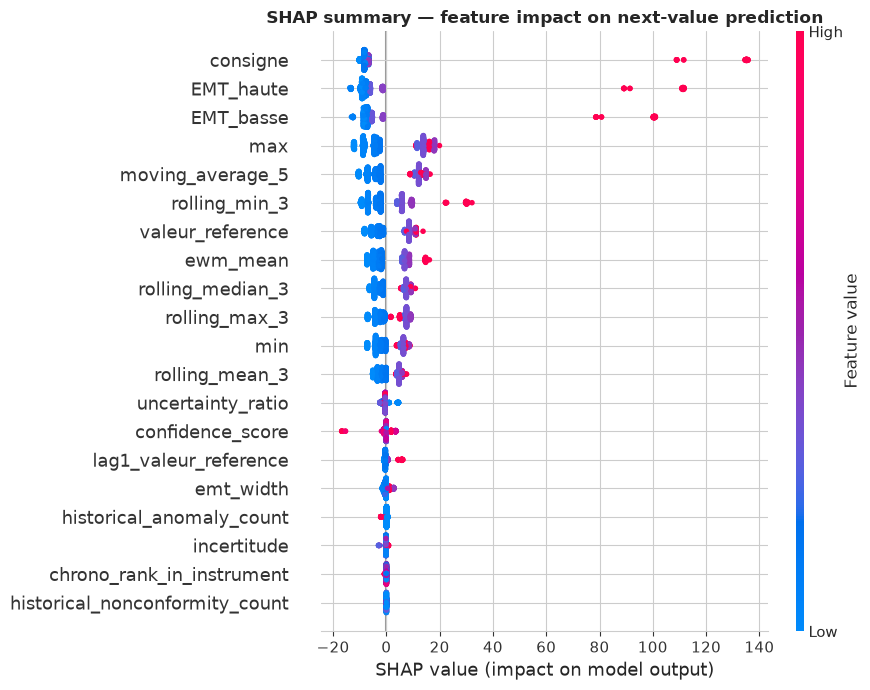

In [14]:

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X)
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=X.columns).sort_values(ascending=False)
display(shap_importance.to_frame("mean_abs_shap"))

fig = plt.figure(figsize=(9, 7))
shap.summary_plot(shap_values, X, show=False, plot_size=None)
plt.title("SHAP summary — feature impact on next-value prediction", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "01_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()


### 5.7 Permutation Importance

In [15]:

perm = permutation_importance(rf, X, y, n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
perm_importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
display(perm_importance.to_frame("permutation_importance"))


,permutation_importance
consigne,1.252027e-01
EMT_haute,8.653038e-02
EMT_basse,7.249222e-02
max,1.214633e-02
rolling_min_3,1.046095e-02
moving_average_5,8.371258e-03
valeur_reference,5.010264e-03
ewm_mean,4.622071e-03
rolling_median_3,3.308926e-03
min,3.075011e-03


### 5.8 SelectKBest (f_regression)

In [16]:

skb = SelectKBest(score_func=f_regression, k=min(10, X.shape[1]))
skb.fit(X, y)
skb_scores = pd.Series(skb.scores_, index=X.columns).sort_values(ascending=False)
skb_selected = X.columns[skb.get_support()].tolist()
print("SelectKBest (f_regression) top features:", skb_selected)
display(skb_scores.to_frame("f_regression_score"))


SelectKBest (f_regression) top features: ['consigne', 'valeur_reference', 'EMT_basse', 'EMT_haute', 'min', 'max', 'rolling_mean_3', 'rolling_median_3', 'rolling_min_3', 'ewm_mean']


,f_regression_score
EMT_basse,76686.959393
EMT_haute,70867.623900
max,10241.492614
valeur_reference,10177.822989
min,10102.995008
rolling_min_3,10097.389363
consigne,9511.281740
ewm_mean,8985.128356
rolling_median_3,8155.618979
rolling_mean_3,7514.574953


### 5.9 PCA (dimensionality overview, not a selection method per se)

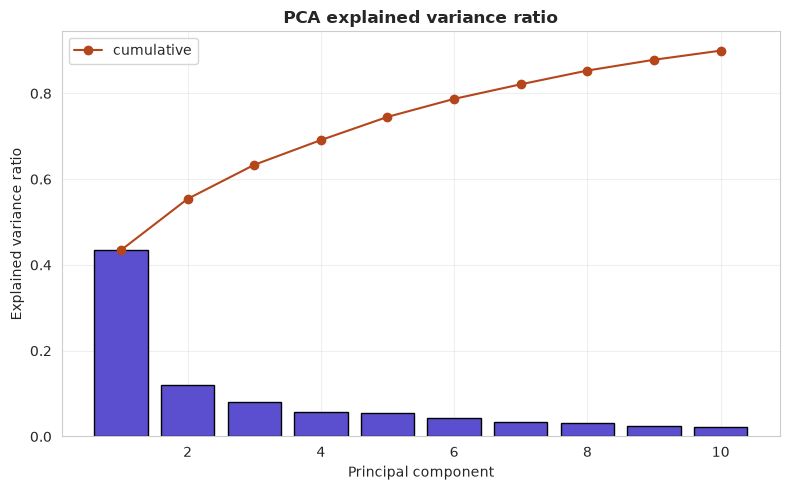

1 principal components explain >= 90% of variance (out of 36 original features) — indicates substantial redundancy among features.


In [17]:

pca = PCA(n_components=min(10, X.shape[1]))
pca.fit(X_scaled)
explained = pca.explained_variance_ratio_
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(range(1, len(explained) + 1), explained, color="#5C4FCF", edgecolor="black")
ax.plot(range(1, len(explained) + 1), np.cumsum(explained), color="#B5451B", marker="o", label="cumulative")
ax.set_title("PCA explained variance ratio", fontsize=12, fontweight="bold")
ax.set_xlabel("Principal component"); ax.set_ylabel("Explained variance ratio")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(REPORTS_FIGURES / "02_pca_explained_variance.png", dpi=150)
plt.show()
n_components_90pct = int(np.argmax(np.cumsum(explained) >= 0.90) + 1)
print(f"{n_components_90pct} principal components explain >= 90% of variance "
      f"(out of {X.shape[1]} original features) — indicates substantial redundancy among features.")


## 6. Consolidated Feature Ranking & Final Selection

In [18]:

def rank_series(s):
    return s.rank(ascending=False, method="min")

ranking = pd.DataFrame({
    "abs_corr": corr_with_target,
    "mutual_info": mi_df,
    "rf_importance": rf_importance,
    "shap": shap_importance,
    "permutation_importance": perm_importance,
    "f_regression": skb_scores,
})
ranking_ranks = ranking.apply(rank_series)
ranking["mean_rank"] = ranking_ranks.mean(axis=1)
ranking["in_rfe_top10"] = ranking.index.isin(rfe_selected)
ranking["in_selectkbest_top10"] = ranking.index.isin(skb_selected)
ranking = ranking.sort_values("mean_rank", kind="mergesort")  # bug fix: default quicksort is NOT stable, so ties in mean_rank (which occur near the selection cutoff) were breaking non-deterministically across runs, silently changing the trained model's column order and metrics between identical re-runs. mergesort is stable, making tie-breaking fully reproducible given the fixed input order above.
display(ranking)

N_FINAL = 12
selected_features = ranking.head(N_FINAL).index.tolist()
print(f"\nFinal selected feature set (top {N_FINAL} by mean rank across 6 methods):")
print(selected_features)

ranking.to_excel(REPORTS_QUALITY / "feature_selection_report.xlsx", sheet_name="feature_ranking")
logger.info("Feature selection report exported. Selected features: %s", selected_features)


,abs_corr,mutual_info,rf_importance,shap,permutation_importance,f_regression,mean_rank,in_rfe_top10,in_selectkbest_top10
EMT_basse,0.995216,2.337412,1.898101e-01,12.148847,7.249222e-02,76686.959393,3.666667,True,True
EMT_haute,0.994826,2.328738,2.115712e-01,13.442327,8.653038e-02,70867.623900,3.666667,True,True
max,0.965763,2.764586,5.013669e-02,8.716662,1.214633e-02,10241.492614,4.000000,True,True
rolling_min_3,0.965300,2.812094,6.771013e-02,6.582676,1.046095e-02,10097.389363,4.833333,False,True
consigne,0.963278,1.815603,2.576635e-01,15.039390,1.252027e-01,9511.281740,5.000000,False,True
valeur_reference,0.965560,2.838116,3.375014e-02,5.540499,5.010264e-03,10177.822989,5.166667,True,True
ewm_mean,0.961251,2.788247,3.801876e-02,5.020735,4.622071e-03,8985.128356,7.000000,False,True
moving_average_5,0.951105,2.653804,4.306906e-02,7.410083,8.371258e-03,7007.318592,8.000000,False,False
min,0.965318,2.691131,2.303813e-02,4.048490,3.075011e-03,10102.995008,8.166667,True,True
rolling_median_3,0.957557,2.765130,2.776751e-02,4.603211,3.308926e-03,8155.618979,8.166667,False,True



Final selected feature set (top 12 by mean rank across 6 methods):
['EMT_basse', 'EMT_haute', 'max', 'rolling_min_3', 'consigne', 'valeur_reference', 'ewm_mean', 'moving_average_5', 'min', 'rolling_median_3', 'rolling_mean_3', 'rolling_max_3']
2026-08-23 00:04:34,099 | INFO | Feature selection report exported. Selected features: ['EMT_basse', 'EMT_haute', 'max', 'rolling_min_3', 'consigne', 'valeur_reference', 'ewm_mean', 'moving_average_5', 'min', 'rolling_median_3', 'rolling_mean_3', 'rolling_max_3']


## 7. Export Feature Tables

In [19]:

full_export_cols = (["id_instrument", "lab_clean", "annee", "point", "chrono_rank_in_instrument"]
                     + candidate_features
                     + ["target_next_valeur_reference", "target_next_erreur", "conforme"])
full_export_cols = [c for c in full_export_cols if c in df.columns]

features_full_path = DATA_PROCESSED / "ILA_features.csv"
df[full_export_cols].to_csv(features_full_path, index=False, encoding="utf-8-sig")
print(f"Exported full feature table: {features_full_path.relative_to(project_root)}  shape={df[full_export_cols].shape}")

selected_export_cols = (["id_instrument", "annee", "chrono_rank_in_instrument"]
                         + selected_features
                         + ["target_next_valeur_reference", "target_next_erreur"])
selected_export_cols = [c for c in selected_export_cols if c in df.columns]
features_selected_path = DATA_PROCESSED / "ILA_features_selected.csv"
supervised_and_inference = df[selected_export_cols]
supervised_and_inference.to_csv(features_selected_path, index=False, encoding="utf-8-sig")
print(f"Exported selected feature table: {features_selected_path.relative_to(project_root)}  shape={supervised_and_inference.shape}")

logger.info("Notebook 04 completed successfully. Final features: %s", selected_features)


Exported full feature table: data/processed/ILA_features.csv  shape=(763, 44)
Exported selected feature table: data/processed/ILA_features_selected.csv  shape=(763, 17)
2026-08-23 00:04:34,145 | INFO | Notebook 04 completed successfully. Final features: ['EMT_basse', 'EMT_haute', 'max', 'rolling_min_3', 'consigne', 'valeur_reference', 'ewm_mean', 'moving_average_5', 'min', 'rolling_median_3', 'rolling_mean_3', 'rolling_max_3']


---
**End of Notebook 04.** Next: Notebook 05 — Regression Model (drift prediction).
